In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 08 · Controls, sensitivity and robustness

Notebook 07 compared representations. Here we ask *why* the comparison came out as it did, and whether it is robust.

1. **Shuffled-week control** - permute the 16 weekly values *inside every row*. Aggregates are preserved, timing is destroyed.
   If lag models exploit timing, they must get worse; if not, shuffling should change nothing.
2. **Anchor-shift (placebo window) sweep** - move the whole 16-week window 2…16 weeks *earlier* (never later: that would leak). If the
   calendar anchoring carries information, the true window (shift 0) should be best.
3. **Window-length sweep** - how many weeks before harvest does a model actually need?
4. **Rolling-origin evaluation** - expanding window, one-year-ahead forecasts for 2011-2017, so conclusions do not hinge on one split.
5. **Heterogeneity** - predominantly irrigated vs rain-fed/mixed states; extreme-rainfall years.
6. **Sensitivity** - drop districts with a poor weather-QC score.
7. **Trend-proxy diagnostic** - does weekly temperature help only because it tracks calendar time?

In [2]:
from src.experiment import *
from src.weather_features import RAIN_LAGS, TMAX_LAGS
M = pd.read_csv(TAB/"p2_main_metrics.csv"); S = pd.read_csv(TAB/"p2_main_summary_test.csv")
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz"); parts = split_frame(D)
pal = {"RF": "#2a9d8f", "XGB": "#e76f51", "Ridge": "#8d99ae"}
Pm = pd.read_csv(PRED/"p2_main_test_predictions.csv.gz")

## 1 · Shuffled-week control (tier C)

saved -> results/figures/p2_08_shuffle_control.png


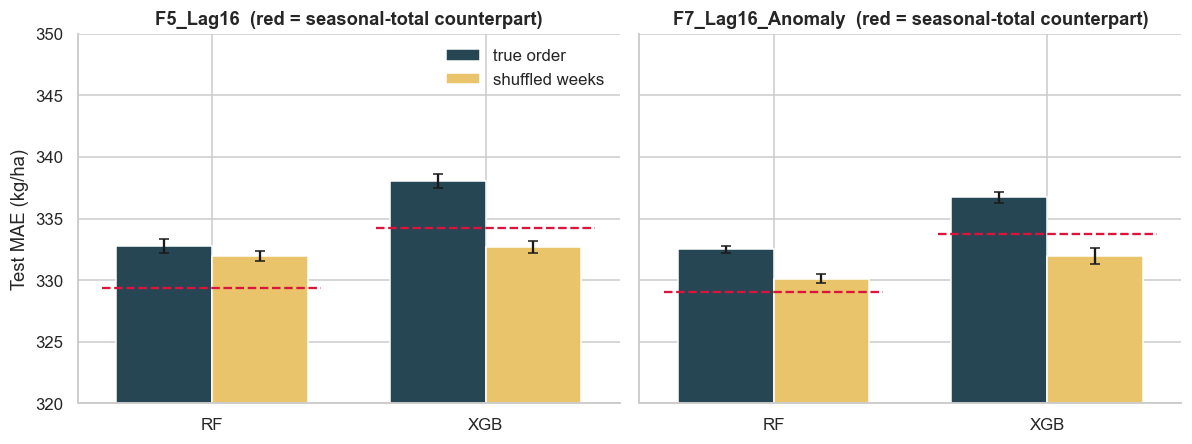

,base,model,condition,mean,std
0,F5_Lag16,RF,shuffled weeks,331.997,0.406
1,F5_Lag16,RF,true order,332.748,0.577
2,F5_Lag16,XGB,shuffled weeks,332.699,0.472
3,F5_Lag16,XGB,true order,338.077,0.563
4,F7_Lag16_Anomaly,RF,shuffled weeks,330.125,0.387
5,F7_Lag16_Anomaly,RF,true order,332.524,0.294
6,F7_Lag16_Anomaly,XGB,shuffled weeks,331.960,0.626
7,F7_Lag16_Anomaly,XGB,true order,336.727,0.467


In [3]:
sh = pd.read_csv(TAB/"p2_control_shuffle_metrics.csv"); sh = sh[sh.split == "test"]
sh["base"] = sh.feature_set.str.replace("__ShuffledWeeks", ""); sh["condition"] = "shuffled weeks"
orig = M[(M.split == "test") & (M.tier == "C_anomaly") & M.feature_set.isin(["F5_Lag16", "F7_Lag16_Anomaly"]) & M.model.isin(["RF", "XGB"])].copy()
orig["base"] = orig.feature_set; orig["condition"] = "true order"
tot = M[(M.split == "test") & (M.tier == "C_anomaly") & M.feature_set.isin(["F1_Aggregate_IMDgrid", "F8_Total_Anomaly"]) & M.model.isin(["RF", "XGB"])].copy()
X = pd.concat([orig, sh]).groupby(["base", "model", "condition"]).MAE.agg(["mean", "std"]).reset_index()
X.to_csv(TAB/"p2_control_shuffle_summary.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, b in zip(axs, ["F5_Lag16", "F7_Lag16_Anomaly"]):
    s = X[X.base == b]
    for k, c in enumerate(["true order", "shuffled weeks"]):
        q = s[s.condition == c].set_index("model").loc[["RF", "XGB"]]
        ax.bar(np.arange(2) + (k - .5) * .35, q["mean"], .35, yerr=q["std"], label=c, color=["#264653", "#e9c46a"][k], capsize=3)
    agg = tot[tot.feature_set == {"F5_Lag16": "F1_Aggregate_IMDgrid", "F7_Lag16_Anomaly": "F8_Total_Anomaly"}[b]].groupby("model").MAE.mean()
    for i, mname in enumerate(["RF", "XGB"]): ax.hlines(agg[mname], i - .4, i + .4, color="crimson", ls="--")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["RF", "XGB"]); ax.set_ylim(320, 350); ax.set_title(b + "  (red = seasonal-total counterpart)")
axs[0].set_ylabel("Test MAE (kg/ha)"); axs[0].legend(frameon=False); plt.tight_layout(); savefig("p2_08_shuffle_control"); plt.show()
X

## 2 · Anchor-shift (placebo window) sweep (tier C)

saved -> results/figures/p2_08_anchor_shift.png


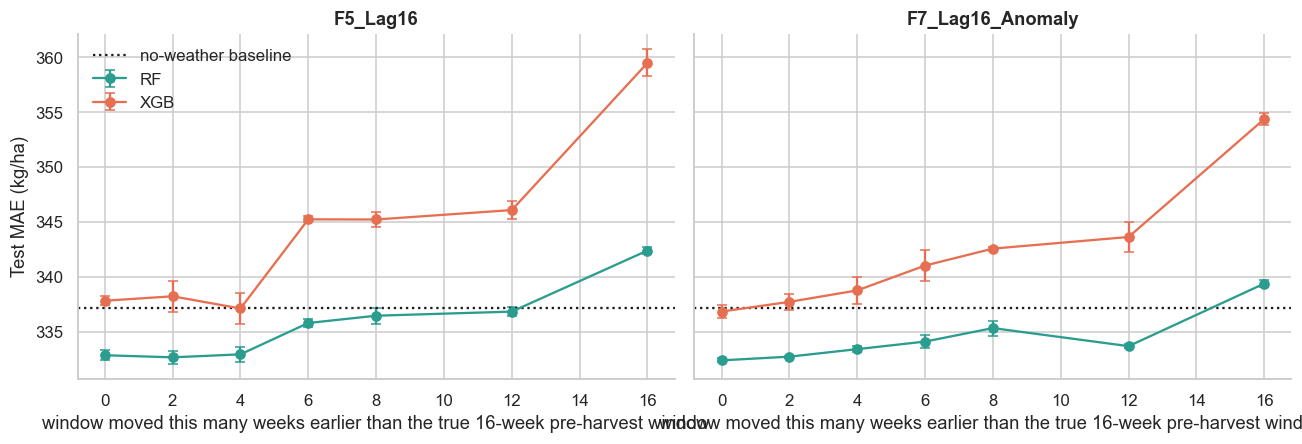

base_feature_set   F5_Lag16         F7_Lag16_Anomaly        
model                    RF     XGB               RF     XGB
anchor_shift_weeks                                          
0                   332.837 337.808          332.369 336.823
2                   332.646 338.215          332.708 337.705
4                   332.919 337.102          333.393 338.752
6                   335.779 345.234          334.084 341.017
8                   336.442 345.219          335.314 342.563
12                  336.818 346.080          333.666 343.623
16                  342.387 359.500          339.372 354.380

In [4]:
an = pd.read_csv(TAB/"p2_control_anchor_shift_metrics.csv"); an = an[an.split == "test"]
g = an.groupby(["base_feature_set", "model", "anchor_shift_weeks"]).MAE.agg(["mean", "std"]).reset_index()
g.to_csv(TAB/"p2_control_anchor_shift_summary.csv", index=False)
ref_tot = S[(S.tier == "C_anomaly") & (S.feature_set == "F8_Total_Anomaly")].set_index("model").MAE
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, b in zip(axs, ["F5_Lag16", "F7_Lag16_Anomaly"]):
    for mod in ["RF", "XGB"]:
        q = g[(g.base_feature_set == b) & (g.model == mod)]
        ax.errorbar(q.anchor_shift_weeks, q["mean"], yerr=q["std"], marker="o", color=pal[mod], label=mod, capsize=3)
    ax.axhline(ref_base := parts["test"].pipe(lambda t: np.abs(t[TARGET] - t[BASE_COL]).mean()), color="k", ls=":", label="no-weather baseline")
    ax.set_xlabel("window moved this many weeks earlier than the true 16-week pre-harvest window"); ax.set_title(b)
axs[0].set_ylabel("Test MAE (kg/ha)"); axs[0].legend(frameon=False); plt.tight_layout(); savefig("p2_08_anchor_shift"); plt.show()
g.pivot_table(index="anchor_shift_weeks", columns=["base_feature_set", "model"], values="mean")

## 3 · Window length (tier C): how far back does it pay to look?

saved -> results/figures/p2_08_window_length.png


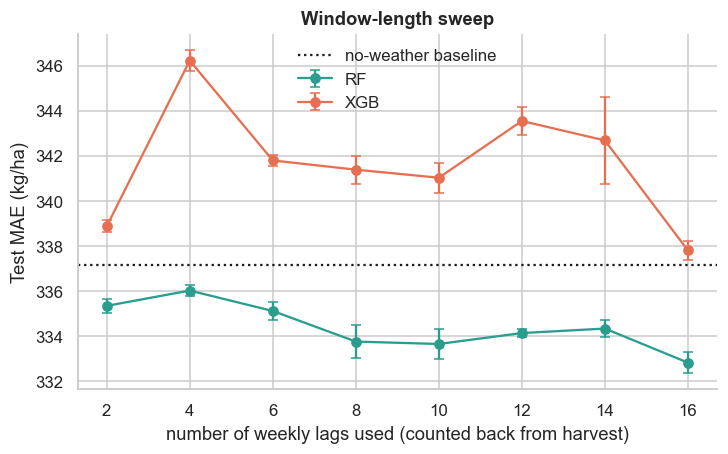

model,RF,XGB
window_weeks,,
2,335.349,338.877
4,336.027,346.231
6,335.123,341.800
8,333.765,341.391
10,333.658,341.033
12,334.143,343.552
14,334.342,342.687
16,332.830,337.808


In [5]:
wl = pd.read_csv(TAB/"p2_window_length_metrics.csv"); wl = wl[wl.split == "test"]
g = wl.groupby(["model", "window_weeks"]).MAE.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for mod in ["RF", "XGB"]:
    q = g[g.model == mod]; ax.errorbar(q.window_weeks, q["mean"], yerr=q["std"], marker="o", label=mod, color=pal[mod], capsize=3)
ax.axhline(np.abs(parts["test"][TARGET] - parts["test"][BASE_COL]).mean(), color="k", ls=":", label="no-weather baseline")
ax.set_xlabel("number of weekly lags used (counted back from harvest)"); ax.set_ylabel("Test MAE (kg/ha)"); ax.legend(frameon=False); ax.set_title("Window-length sweep")
savefig("p2_08_window_length"); plt.show(); g.pivot(index="window_weeks", columns="model", values="mean")

## 4 · Rolling-origin evaluation: one-year-ahead forecasts 2011-2017

In [6]:
ro = pd.read_csv(TAB/"p2_rolling_origin_predictions.csv.gz")
ro["ae"] = (ro.Actual - ro.Predicted).abs()
# average seeds first (ensemble), then score
g = ro.groupby(["tier", "feature_set", "model", "test_year", "stable_geographic_id"], as_index=False).agg(Actual=("Actual", "first"), Predicted=("Predicted", "mean"))
g["ae"] = (g.Actual - g.Predicted).abs()
yr = g.groupby(["tier", "feature_set", "model", "test_year"]).ae.mean().reset_index()
tabl = yr.groupby(["tier", "feature_set", "model"]).ae.mean().unstack("feature_set").round(1)
tabl.to_csv(TAB/"p2_rolling_origin_summary.csv"); tabl

feature_set           F0_Aggregate_IMD  F1_Aggregate_IMDgrid  F5_Lag16  F7_Lag16_Anomaly  F8_Total_Anomaly
tier           model                                                                                      
A_weather_only RF              639.100               650.800   665.800           635.300           664.900
               XGB             640.100               646.800   652.100           621.900           661.200
C_anomaly      RF              335.400               335.900   338.900           337.700           335.400
               XGB             338.100               338.000   343.700           341.000           337.900

saved -> results/figures/p2_08_rolling_origin.png


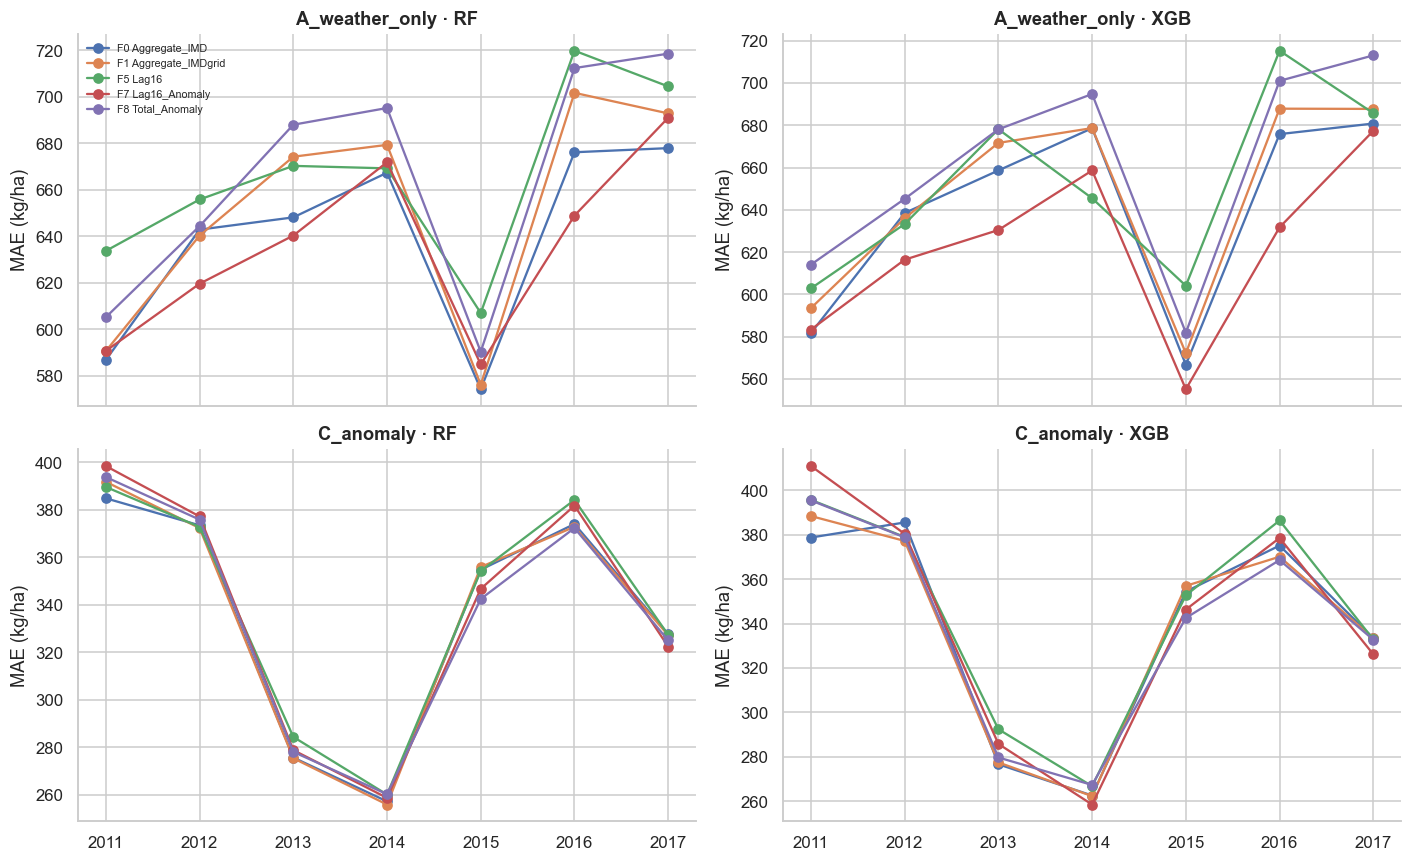

,tier,model,A,B,delta_mae,ci_lo,ci_hi,p_boot
0,A_weather_only,RF,F5_Lag16,F1_Aggregate_IMDgrid,15.047,2.804,26.900,0.018
1,A_weather_only,RF,F5_Lag16,F0_Aggregate_IMD,26.862,13.469,40.029,0.000
2,A_weather_only,RF,F7_Lag16_Anomaly,F8_Total_Anomaly,-29.809,-43.698,-16.140,0.000
3,A_weather_only,XGB,F5_Lag16,F1_Aggregate_IMDgrid,5.409,-2.855,13.143,0.189
4,A_weather_only,XGB,F5_Lag16,F0_Aggregate_IMD,12.156,0.800,23.730,0.037
5,A_weather_only,XGB,F7_Lag16_Anomaly,F8_Total_Anomaly,-39.488,-52.963,-25.996,0.000
6,C_anomaly,RF,F5_Lag16,F1_Aggregate_IMDgrid,3.073,1.309,4.918,0.000
7,C_anomaly,RF,F5_Lag16,F0_Aggregate_IMD,3.595,1.439,5.850,0.001
8,C_anomaly,RF,F7_Lag16_Anomaly,F8_Total_Anomaly,2.335,-0.192,4.863,0.076
9,C_anomaly,XGB,F5_Lag16,F1_Aggregate_IMDgrid,5.765,2.380,9.213,0.001


In [7]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for r_, tier in enumerate(["A_weather_only", "C_anomaly"]):
    for c_, mod in enumerate(["RF", "XGB"]):
        ax = axs[r_, c_]
        for fs in ["F0_Aggregate_IMD", "F1_Aggregate_IMDgrid", "F5_Lag16", "F7_Lag16_Anomaly", "F8_Total_Anomaly"]:
            q = yr[(yr.tier == tier) & (yr.model == mod) & (yr.feature_set == fs)]; ax.plot(q.test_year, q.ae, marker="o", label=fs.split("_")[0] + " " + "_".join(fs.split("_")[1:]))
        ax.set_title(f"{tier} · {mod}"); ax.set_ylabel("MAE (kg/ha)")
axs[0, 0].legend(fontsize=7, frameon=False); plt.tight_layout(); savefig("p2_08_rolling_origin"); plt.show()
rows = []
for tier in ["A_weather_only", "C_anomaly"]:
    for mod in ["RF", "XGB"]:
        for a, b in [("F5_Lag16", "F1_Aggregate_IMDgrid"), ("F5_Lag16", "F0_Aggregate_IMD"), ("F7_Lag16_Anomaly", "F8_Total_Anomaly")]:
            ea = g[(g.tier == tier) & (g.model == mod) & (g.feature_set == a)].set_index(["test_year", "stable_geographic_id"]).ae
            eb = g[(g.tier == tier) & (g.model == mod) & (g.feature_set == b)].set_index(["test_year", "stable_geographic_id"]).ae
            idx = ea.index.intersection(eb.index)
            rows.append(dict(tier=tier, model=mod, A=a, B=b, **paired_cluster_bootstrap(ea.loc[idx].values, eb.loc[idx].values, np.array([i[1] for i in idx]))))
RB = pd.DataFrame(rows); RB.to_csv(TAB/"p2_rolling_origin_bootstrap.csv", index=False); RB

## 5 · Heterogeneity

### 5a · Predominantly irrigated vs rain-fed/mixed states
States are grouped with a coarse, externally-known classification (no district-level irrigation data exist in the supplied dataset - a
stated limitation): *predominantly irrigated* rice states (Punjab, Haryana, Uttar Pradesh, Andhra Pradesh, Telangana, Tamil Nadu) versus the rest
(rain-fed or mixed). The hypothesis is that rainfall timing matters mainly where fields depend on the monsoon.

In [8]:
IRR = {"Punjab", "Haryana", "Uttar Pradesh", "Andhra Pradesh", "Telangana", "Tamil Nadu"}
Pm["group"] = np.where(Pm.State_Clean.isin(IRR), "irrigated", "rain-fed / mixed")
def grp_mae(tier, fs, mod):
    x = Pm[(Pm.tier == tier) & (Pm.feature_set == fs) & (Pm.model == mod)].groupby(["group", "stable_geographic_id", "Year"]).agg(y=("Actual", "first"), p=("Predicted", "mean")).reset_index()
    x["ae"] = (x.y - x.p).abs(); return x.groupby("group").ae.mean()
rows = []
for tier in ["C_anomaly"]:
    for mod in ["RF", "XGB", "Ridge"]:
        for fs in ["F0_Aggregate_IMD", "F1_Aggregate_IMDgrid", "F5_Lag16", "F7_Lag16_Anomaly", "F8_Total_Anomaly"]:
            for gname, v in grp_mae(tier, fs, mod).items(): rows.append(dict(tier=tier, model=mod, feature_set=fs, group=gname, MAE=v))
H = pd.DataFrame(rows); base_g = parts["test"].assign(group=lambda t: np.where(t.State_Clean.isin(IRR), "irrigated", "rain-fed / mixed")).groupby("group").apply(lambda t: np.abs(t[TARGET] - t[BASE_COL]).mean())
print("no-weather baseline MAE by group:", base_g.round(1).to_dict())
Hp = H.pivot_table(index=["model", "feature_set"], columns="group", values="MAE"); Hp["irrigated Δ vs baseline"] = Hp["irrigated"] - base_g["irrigated"]; Hp["rain-fed Δ vs baseline"] = Hp["rain-fed / mixed"] - base_g["rain-fed / mixed"]
Hp.to_csv(TAB/"p2_heterogeneity_irrigation.csv"); Hp.round(1)

no-weather baseline MAE by group: {'irrigated': 315.2, 'rain-fed / mixed': 348.2}


group                       irrigated  rain-fed / mixed  irrigated Δ vs baseline  rain-fed Δ vs baseline
model feature_set                                                                                       
RF    F0_Aggregate_IMD        298.500           344.800                  -16.700                  -3.400
      F1_Aggregate_IMDgrid    294.400           346.900                  -20.800                  -1.300
      F5_Lag16                303.900           347.000                  -11.300                  -1.200
      F7_Lag16_Anomaly        303.400           347.000                  -11.800                  -1.300
      F8_Total_Anomaly        294.800           346.100                  -20.400                  -2.100
Ridge F0_Aggregate_IMD        302.800           348.500                  -12.400                   0.200
      F1_Aggregate_IMDgrid    302.800           347.600                  -12.400                  -0.700
      F5_Lag16                307.400           347.800                   -7.800                  -0.500
      F7_Lag16_Anomaly        305.900           345.500                   -9.300                  -2.800
      F8_Total_Anomaly        301.200           346.200                  -14.000                  -2.100
XGB   F0_Aggregate_IMD        300.500           347.200                  -14.700                  -1.000
      F1_Aggregate_IMDgrid    293.500           353.900                  -21.700                   5.700
      F5_Lag16                302.800           354.200                  -12.400                   6.000
      F7_Lag16_Anomaly        296.300           355.700                  -18.900                   7.400
      F8_Total_Anomaly        296.700           352.000                  -18.500                   3.800

### 5b · State-level gain of weather over the no-weather baseline (tier C, best aggregate vs lag, RF)

saved -> results/figures/p2_08_state_gain.png


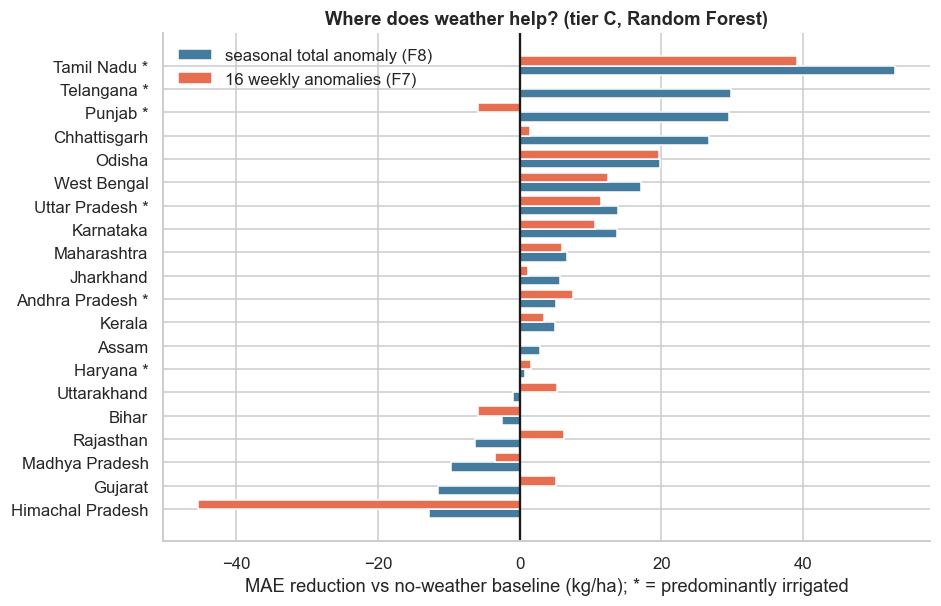

,baseline,F8 total anomaly,F7 lag anomalies,F5 raw lags,gain_F8,gain_F7,F7 vs F8
State_Clean,,,,,,,
Himachal Pradesh,132.000,144.900,177.500,163.900,-12.900,-45.400,-32.600
Gujarat,285.500,297.100,280.300,281.800,-11.600,5.200,16.700
Madhya Pradesh,610.900,620.600,614.400,613.600,-9.700,-3.500,6.200
Rajasthan,303.000,309.300,296.700,294.000,-6.300,6.300,12.500
Bihar,382.900,385.400,388.800,389.700,-2.500,-5.900,-3.400
Uttarakhand,96.700,97.600,91.400,88.000,-0.900,5.300,6.200
Haryana,262.100,261.400,260.500,263.900,0.700,1.600,0.900
Assam,149.200,146.300,149.300,147.000,2.900,-0.200,-3.100
Kerala,163.600,158.700,160.200,162.900,4.900,3.400,-1.500


In [9]:
def state_mae(fs, mod="RF", tier="C_anomaly"):
    x = Pm[(Pm.tier == tier) & (Pm.feature_set == fs) & (Pm.model == mod)].groupby(["State_Clean", "stable_geographic_id", "Year"]).agg(y=("Actual", "first"), p=("Predicted", "mean")).reset_index()
    x["ae"] = (x.y - x.p).abs(); return x.groupby("State_Clean").ae.mean()
t = parts["test"]; b = t.groupby("State_Clean").apply(lambda z: np.abs(z[TARGET] - z[BASE_COL]).mean())
SM = pd.DataFrame({"baseline": b, "F8 total anomaly": state_mae("F8_Total_Anomaly"), "F7 lag anomalies": state_mae("F7_Lag16_Anomaly"), "F5 raw lags": state_mae("F5_Lag16")})
SM["gain_F8"] = SM.baseline - SM["F8 total anomaly"]; SM["gain_F7"] = SM.baseline - SM["F7 lag anomalies"]; SM["F7 vs F8"] = SM["F8 total anomaly"] - SM["F7 lag anomalies"]
SM = SM.sort_values("gain_F8"); SM.to_csv(TAB/"p2_heterogeneity_by_state.csv")
fig, ax = plt.subplots(figsize=(9, 6)); y = np.arange(len(SM))
ax.barh(y - .2, SM.gain_F8, .4, label="seasonal total anomaly (F8)", color="#457b9d"); ax.barh(y + .2, SM.gain_F7, .4, label="16 weekly anomalies (F7)", color="#e76f51")
ax.set_yticks(y); ax.set_yticklabels([f"{s}{' *' if s in IRR else ''}" for s in SM.index]); ax.axvline(0, color="k"); ax.legend(frameon=False)
ax.set_xlabel("MAE reduction vs no-weather baseline (kg/ha); * = predominantly irrigated"); ax.set_title("Where does weather help? (tier C, Random Forest)")
savefig("p2_08_state_gain"); plt.show(); SM.round(1)

### 5c · Extreme rainfall years (tail of the 16-week total anomaly, thresholds from training years)

In [10]:
from src.experiment import add_rain_anomalies
Dd = add_rain_anomalies(D, 2009); trn = Dd[Dd.Year <= 2009]
z = trn.Rain_Anom_Total16 / trn.groupby("stable_geographic_id").Rain_Anom_Total16.transform("std").clip(lower=1)    # not needed for thresholds
lo, hi = trn.Rain_Anom_Total16.quantile([.1, .9]); ts = Dd[Dd.Year >= 2014].copy()
ts["regime"] = np.where(ts.Rain_Anom_Total16 <= lo, "dry tail (≤P10)", np.where(ts.Rain_Anom_Total16 >= hi, "wet tail (≥P90)", "normal"))
reg = ts.set_index(["stable_geographic_id", "Year"]).regime
rows = []
for fs in ["F0_Aggregate_IMD", "F1_Aggregate_IMDgrid", "F5_Lag16", "F7_Lag16_Anomaly", "F8_Total_Anomaly"]:
    for mod in ["RF", "XGB"]:
        x = Pm[(Pm.tier == "C_anomaly") & (Pm.feature_set == fs) & (Pm.model == mod)].groupby(["stable_geographic_id", "Year"]).agg(y=("Actual", "first"), p=("Predicted", "mean"))
        x["ae"] = (x.y - x.p).abs(); x["regime"] = reg.reindex(x.index).values
        for r_, v in x.groupby("regime").ae.mean().items(): rows.append(dict(feature_set=fs, model=mod, regime=r_, MAE=v))
bl = ts.assign(ae=(ts[TARGET] - ts[BASE_COL]).abs()).groupby("regime").ae.mean()
R = pd.DataFrame(rows).pivot_table(index=["model", "feature_set"], columns="regime", values="MAE"); R.loc[("—", "no-weather baseline"), :] = bl
print("share of test rows by regime:", ts.regime.value_counts(normalize=True).round(3).to_dict()); R.to_csv(TAB/"p2_extreme_regime_mae.csv"); R.round(1)

share of test rows by regime: {'normal': 0.784, 'dry tail (≤P10)': 0.165, 'wet tail (≥P90)': 0.052}


regime                      dry tail (≤P10)  normal  wet tail (≥P90)
model feature_set                                                   
RF    F0_Aggregate_IMD              315.500 330.900          348.800
      F1_Aggregate_IMDgrid          315.400 330.900          350.400
      F5_Lag16                      323.900 332.900          356.100
      F7_Lag16_Anomaly              318.200 334.000          353.400
      F8_Total_Anomaly              309.100 331.300          357.000
XGB   F0_Aggregate_IMD              316.600 333.500          350.300
      F1_Aggregate_IMDgrid          320.800 335.100          353.600
      F5_Lag16                      324.300 338.300          358.400
      F7_Lag16_Anomaly              314.100 338.800          358.800
      F8_Total_Anomaly              315.900 335.100          364.600
—     no-weather baseline           322.500 338.200          368.000

## 6 · Sensitivity: exclude districts with weak weather-QC

In [11]:
flag = set(pd.read_csv(TAB/"p2_flagged_low_qc_districts.csv").stable_geographic_id)
rows = []
for tier in ["A_weather_only", "C_anomaly"]:
    for mod in ["RF", "XGB"]:
        for fs in ["F0_Aggregate_IMD", "F1_Aggregate_IMDgrid", "F5_Lag16", "F7_Lag16_Anomaly", "F8_Total_Anomaly"]:
            x = Pm[(Pm.tier == tier) & (Pm.feature_set == fs) & (Pm.model == mod)].groupby(["stable_geographic_id", "Year"]).agg(y=("Actual", "first"), p=("Predicted", "mean")).reset_index()
            x["ae"] = (x.y - x.p).abs()
            rows.append(dict(tier=tier, model=mod, feature_set=fs, MAE_all=x.ae.mean(), MAE_clean=x[~x.stable_geographic_id.isin(flag)].ae.mean(), n_excluded_rows=int(x.stable_geographic_id.isin(flag).sum())))
Sn = pd.DataFrame(rows); Sn.to_csv(TAB/"p2_sensitivity_qc_excluded.csv", index=False)
Sn.pivot_table(index=["tier", "model"], columns="feature_set", values="MAE_clean").round(1)

feature_set           F0_Aggregate_IMD  F1_Aggregate_IMDgrid  F5_Lag16  F7_Lag16_Anomaly  F8_Total_Anomaly
tier           model                                                                                      
A_weather_only RF              731.500               744.700   748.300           720.600           760.400
               XGB             737.300               739.400   746.300           711.200           754.600
C_anomaly      RF              329.700               329.500   332.700           332.500           329.300
               XGB             332.200               333.800   336.900           336.300           333.900

## 7 · Trend-proxy diagnostic - why do temperature lags help tier A?

In tier A (level target) the variants with weekly *temperature* lags (F6) or *anomaly* lags (F7) look better than the others.
That could be a genuine weather effect, or it could be that weekly Tmax simply encodes **calendar time** (warming trend and
instrument/reanalysis drift) and therefore proxies the technological yield trend that tier A cannot otherwise see.

In [12]:
tm = D[TMAX_LAGS].mean(axis=1)
print("corr(mean weekly Tmax in lag window, Year)      :", round(np.corrcoef(tm, D.Year)[0, 1], 3))
dm = D.assign(tm=tm); dm["tm_anom"] = dm.tm - dm.groupby("stable_geographic_id").tm.transform("mean")
print("within-district corr(Tmax anomaly, Year)        :", round(np.corrcoef(dm.tm_anom, dm.Year)[0, 1], 3))
dm["ra"] = D.assign(ra=add_rain_anomalies(D, 2009).Rain_Anom_Total16).ra.values
print("within-district corr(16-week rain anomaly, Year)  :", round(np.corrcoef(dm.ra, dm.Year)[0, 1], 3), " (no rainfall trend)" if abs(np.corrcoef(dm.ra, dm.Year)[0, 1]) < .1 else "")
print("share of districts whose Tmax-window mean rises with Year (slope>0):", round((dm.groupby("stable_geographic_id").apply(lambda z: np.polyfit(z.Year, z.tm, 1)[0] if len(z) > 5 else np.nan) > 0).mean(), 3))

corr(mean weekly Tmax in lag window, Year)      : 0.132
within-district corr(Tmax anomaly, Year)        : 0.393
within-district corr(16-week rain anomaly, Year)  : -0.107 
share of districts whose Tmax-window mean rises with Year (slope>0): 0.977


### Take-aways of notebook 08
See the computed tables. In short: the controls tell us whether (and where) timing information exists; the rolling-origin and QC
sensitivity tell us whether that conclusion is stable; the trend-proxy diagnostic tells us how to read the tier-A temperature effect.